# Signals: 50 companies from S&P500 vs SPUS
#### signal generally refers to a quantity deemed useful to make a prediciton on a stock or market.

### Useful definitions:
returns $r$ are calculated in a day.  
$$ r_j(t) =  \log P_j(t) - \log P_j(t-1) $$
$P_j(t)$ adjusted closing day price of asset $j$ at $t$.  


<u> Momentum: </u> Tendency of a stock to move in a direction. 
$$ m_j(t) = \sum_{k<K}^{L+K}r_j(t-k) $$
$$ = \log P_j(t-K) - \log P_j (t-L-K) $$
$L$ days: window excluding recent $K$ days.  


<u> Cross-sectional normalization: </u> Stock residuals from mean within a universe $M$ weighted by its spread. Equivalent to pulls, or weighted residuals in scientific literature (observation-model/uncertainty) with the model here being the null hypothesis i.e. all stocks are assumed to behave similarly on average. "If all signals move together, this should be 0".
$$ z_j(t) = \frac{x_j(t) - \mu(t)}{\sigma(t)} $$
$\mu(t) = \frac{1}{N} \sum_i x_i(t) $ with $x$ being a signal  
$\sigma(t) = \sqrt{\frac{1}{N} \sum_i (x_i(t) - \mu(t))^2 }$

<u> Short term reversal: </u> Negative of recent cumulative returns over a short window $W$. Negative sign converts underperforming assests into long candidates. The idea is to see if a stock will bounce back after dropping or the inverse.  

$$ v_j(t) = - \sum_{k=0}^{W-1}r_j(t-k) $$
$$ = - [ \log P_j(t) - \log P_j(t-W) ] $$


<u> Volatility: </u> Can be defined in multiple ways depending on the model (see 02_volatility.py). Estimates fluctuations of a stock within a window of $H$ days. Generally, $H=21$ days referring to the trading days in a month and $252$ for a year.
$$ \hat{\sigma}_j (t) = \sqrt{ \frac{1}{H} \sum_{k=1}^{H} \left( r_j(t-k) - \bar{r}_j \right)^2 } $$
Can define a signal as $u_j(t) = -\hat{\sigma}_j (t)$

### Common performance metrics:

<u> Annualised Sharpe ratio: </u>  
Let $\{r(t)\}_{t=1}^N$ denote the time series of the daily portfolio returns with $N$ being the number of "observed" days. The annualised Sharpe ratio is:  
$$ \hat{S} = \frac{\hat{\mu}}{\sqrt{T}\hat{\sigma}} $$
$\hat{\mu} = \frac{1}{N}\sum_t r(t)$  
$\hat{\sigma} = \sqrt{\frac{1}{N} \sum_t (r(t) -\hat{\mu})^2 }$  
$T=252$ number of trading days a year  
<br>
The standard error for a sample with $N$ observations is:
$$ SE(\hat{S}) \approx \sqrt{\frac{1}{N} \left( 1+ \frac{\hat{S}}{2} \right)^2 } $$   
<br>

<u> Compound annual growth rate: </u>  
Constant annual returns that would reproduce the observed terminal wealth.
$$ CAGR = W^{\frac{T}{N}} - 1 $$
$ W = \prod_{t=1}^N (1+r(t)) $ the wealth factor for $N$ daily returns  
$T=252$ number of trading days a year  
<br>

<u> Maximum drawdown: </u>  
Calculates the worst peak-to-trough during a sample period. Maximum drawdown over the sample period:
$$ MDD = \min_t DD(t) $$
$$ DD = \frac{W(t) - M(t)}{M(t)} $$
with  
$W = \prod_{k=1}^{t}(1+r(k))$ the wealth process   
$ M(t) = \max_{k \leq t} W(k)$
<br>

<u> Portfolio turnover: </u>  
Calculates how many trades are conducted to change your portfolio over a given period. Based on the weight of an asset $j$ denoted as $w_j(t)$: the percentage of the protfolio capital invested in asset $j$.  
One-way daily turnover:
$$ \tau(t) = \sum_j |w_j(t) - w_j(t-1)| $$
Different trades will cost a transaction fee. Assuming its cost is a constant, the net returns are calculated as:  
$$ r_{\rm net}(t) = r_{\rm gross}(t) - c\tau(t) $$ 
$r_{\rm gross}(t)$ is the returns before transaction fees  
$c$ is the transaction fee  
<br>
You can calculate the Sharpe ratio over the net return to estimate the performance of the strategy after transactions. The quantity $S_{\rm gross} - S_{\rm net}$ evaluates the impact of the transaction fees and assesses whether a signal is economically exploitable.

## Imports

In [70]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data import download_prices, compute_returns
from universe import get_universe, universe_diff
from metrics import sharpe_ratio, annualised_return, max_drawdown, summary
from volatility import (
    rolling_vol, ewma_vol,
    fit_garch_universe, garch_conditional_vol,
    compare_universes
)
from signals import cross_section_zscore, momentum, short_term_reversal, volatility_signal

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
print('Imports OK')

Imports OK


## Dowload data

In [3]:
sp500_tickers = get_universe('sp500')
spus_tickers  = get_universe('spus')

all_tickers  = list(set(sp500_tickers + spus_tickers))
prices_all   = download_prices(all_tickers, start='2015-01-01')

sp500_cols   = [t for t in sp500_tickers if t in prices_all.columns]
spus_cols    = [t for t in spus_tickers  if t in prices_all.columns]

ret_sp500 = compute_returns(prices_all[sp500_cols])
ret_spus  = compute_returns(prices_all[spus_cols])

print(f'SP500: {ret_sp500.shape[1]} stocks | SPUS: {ret_spus.shape[1]} stocks')

Loading from cache: prices_2015-01-01_today.csv
SP500: 49 stocks | SPUS: 39 stocks


In [4]:
all_tickers = list(set(sp500_tickers + spus_tickers))
prices_all = download_prices(all_tickers, start='2015-01-01')  # Calculating prices from 2015, can be changed to eplore more backtesting options

sp500_cols = [t for t in sp500_tickers if t in prices_all.columns] # S&P 500
spus_cols  = [t for t in spus_tickers  if t in prices_all.columns] # SPUS

prices_sp500 = prices_all[sp500_cols]
prices_spus  = prices_all[spus_cols]
returns_sp500 = compute_returns(prices_sp500)
returns_spus  = compute_returns(prices_spus)

print(f'SP500: {prices_sp500.shape[1]} stocks, {prices_sp500.shape[0]} days')
print(f'SPUS : {prices_spus.shape[1]} stocks, {prices_spus.shape[0]} days')

Loading from cache: prices_2015-01-01_today.csv
SP500: 49 stocks, 2960 days
SPUS : 39 stocks, 2960 days


In [5]:
# Displaying data

In [6]:
prices_sp500.head()

,AAPL,MSFT,NVDA,AMZN,GOOGL,META,TSLA,UNH,LLY,JPM,...,AMGN,RTX,QCOM,HON,UPS,LOW,SPGI,GS,MS,BLK
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,24.171755,39.607178,0.481884,15.4260,26.227926,77.705750,14.620667,82.842613,57.200382,45.838116,...,114.101768,55.171227,53.498501,74.171104,71.034050,54.643379,74.781776,154.117889,28.250025,266.834656
2015-01-05,23.490803,39.242943,0.473745,15.1095,25.728178,76.457718,14.006000,81.478065,56.637035,44.415054,...,112.745926,54.250431,53.246407,72.757668,69.611816,53.335819,73.457504,149.305847,27.366976,259.930725
2015-01-06,23.493008,38.666973,0.459382,14.7645,25.093222,75.427574,14.085333,81.313660,56.922810,43.263412,...,109.113533,53.483093,52.490189,72.587479,69.154892,53.456886,72.394730,146.285477,26.578806,255.891479
2015-01-07,23.822437,39.158249,0.458185,14.9210,25.019424,75.427574,14.063333,82.143875,56.522747,43.329441,...,112.924301,54.063374,53.102379,73.112862,69.798454,55.046944,73.356300,148.465546,26.958288,261.306946
2015-01-08,24.737749,40.310211,0.475420,15.0230,25.106596,77.438324,14.041333,86.064888,57.861702,44.297695,...,112.517540,54.984188,53.664135,74.444893,71.053345,56.209232,74.014191,150.835861,27.359674,264.358826


In [9]:
returns_spus.head()

,AAPL,MSFT,NVDA,AMZN,GOOGL,META,TSLA,UNH,LLY,XOM,...,DHR,NEE,TXN,INTC,AMGN,QCOM,HON,UPS,LOW,SPGI
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-05,-0.028576,-0.009239,-0.017034,-0.020731,-0.019238,-0.016191,-0.042950,-0.016609,-0.009897,-0.027743,...,-0.009966,-0.010648,-0.015641,-0.011340,-0.011954,-0.004723,-0.019240,-0.020225,-0.024220,-0.017867
2015-01-06,0.000094,-0.014786,-0.030787,-0.023098,-0.024989,-0.013565,0.005648,-0.002020,0.005033,-0.005330,...,-0.006857,0.003877,-0.016662,-0.018813,-0.032748,-0.014304,-0.002342,-0.006586,0.002267,-0.014574
2015-01-07,0.013925,0.012625,-0.002609,0.010544,-0.002945,0.000000,-0.001563,0.010158,-0.007053,0.010082,...,0.006033,0.009112,0.017801,0.020758,0.034329,0.011595,0.007212,0.009263,0.029311,0.013195
2015-01-08,0.037703,0.028994,0.036927,0.006813,0.003478,0.026309,-0.001566,0.046629,0.023413,0.016507,...,0.015330,0.006060,0.016185,0.018430,-0.003609,0.010523,0.018055,0.017819,0.020895,0.008928
2015-01-09,0.001072,-0.008441,0.004020,-0.011818,-0.012287,-0.005644,-0.018981,-0.009404,-0.013352,-0.001411,...,-0.006759,-0.008869,0.000559,0.001906,-0.012380,-0.001208,-0.016739,-0.007363,-0.018990,-0.008583


## Prices

In [55]:
columns_not_in_both = set(prices_sp500.columns) ^ set(prices_spus.columns)
prices_diff = pd.concat(
    [prices_sp500.reindex(columns=columns_not_in_both),
     prices_spus.reindex(columns=columns_not_in_both)],
    axis=0
)

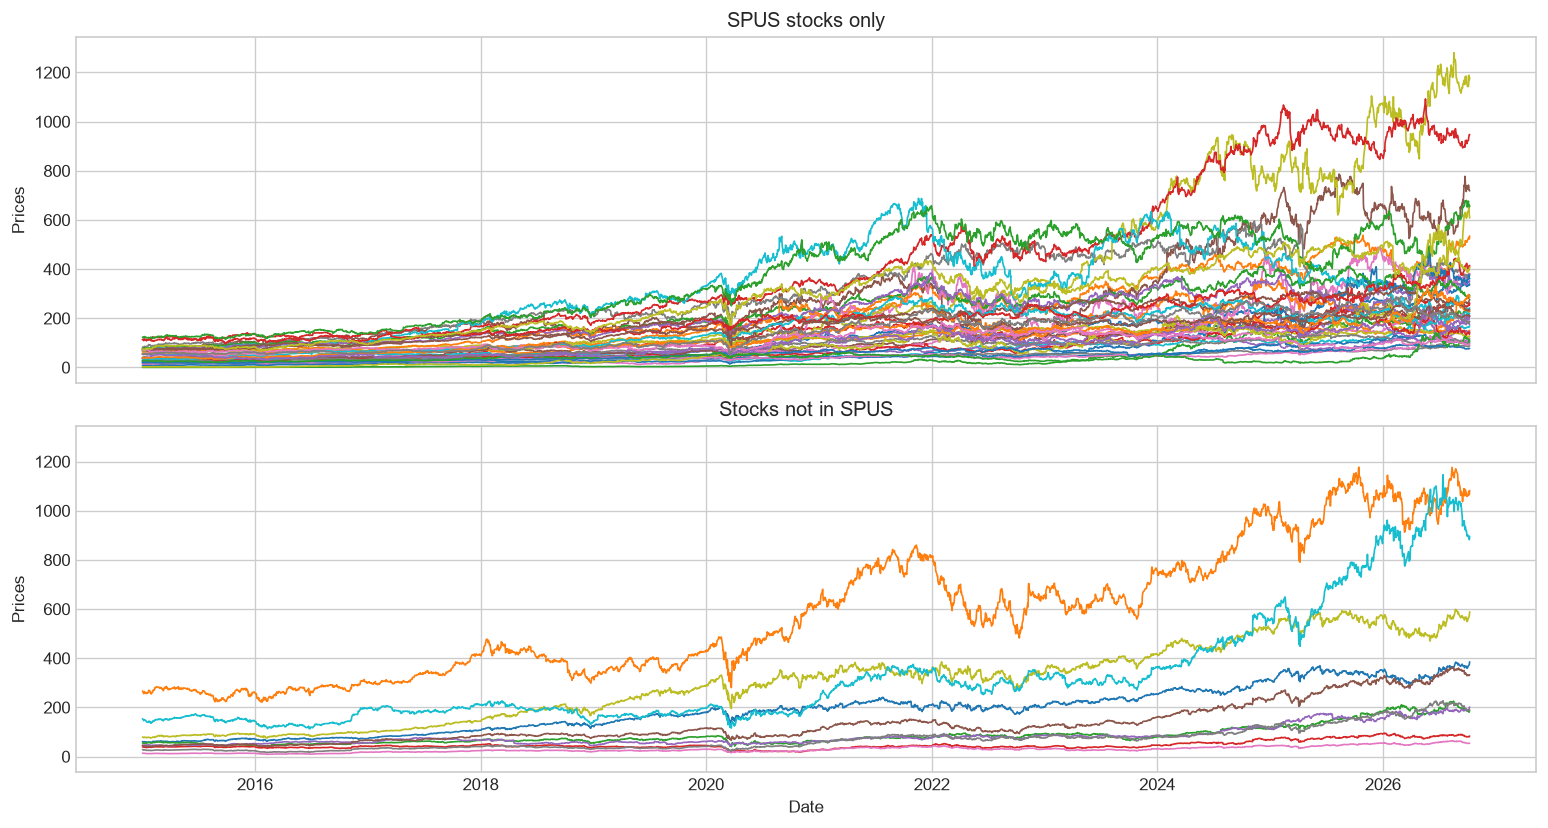

In [60]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True)
axes[0].plot(prices_spus, lw=1)
axes[0].set_ylabel('Prices')
axes[0].set_title('SPUS stocks only')
axes[1].plot(prices_diff, lw=1)
axes[1].set_ylabel('Prices')
axes[1].set_xlabel('Date')
axes[1].set_title('Stocks not in SPUS')
plt.tight_layout()

## Returns

In [57]:
returns_diff = pd.concat(
    [returns_sp500.reindex(columns=columns_not_in_both),
     returns_spus.reindex(columns=columns_not_in_both)],
    axis=0
)

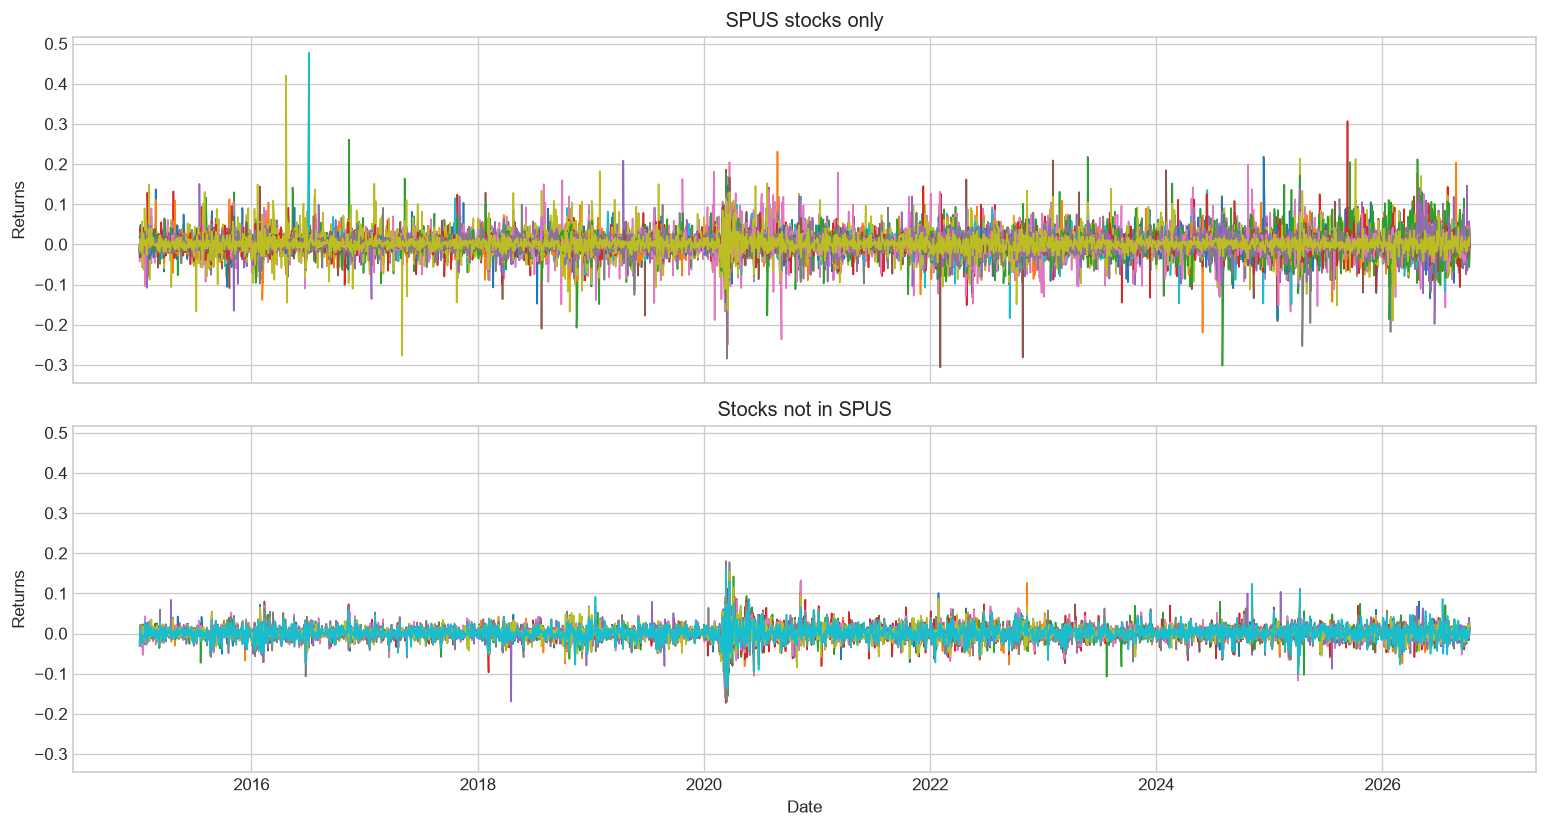

In [59]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True)
axes[0].plot(returns_spus, lw=1)
axes[0].set_ylabel('Returns')
axes[0].set_title('SPUS stocks only')
axes[1].plot(returns_diff, lw=1)
axes[1].set_ylabel('Returns')
axes[1].set_xlabel('Date')
axes[1].set_title('Stocks not in SPUS')
plt.tight_layout()

## Momentum

In [62]:
mom_sp500 = momentum(returns_sp500)
mom_spus = momentum(returns_spus)

In [50]:
columns_not_in_both = set(mom_sp500.columns) ^ set(mom_spus.columns)
mom_diff = pd.concat(
    [mom_sp500.reindex(columns=columns_not_in_both),
     mom_spus.reindex(columns=columns_not_in_both)],
    axis=0
)

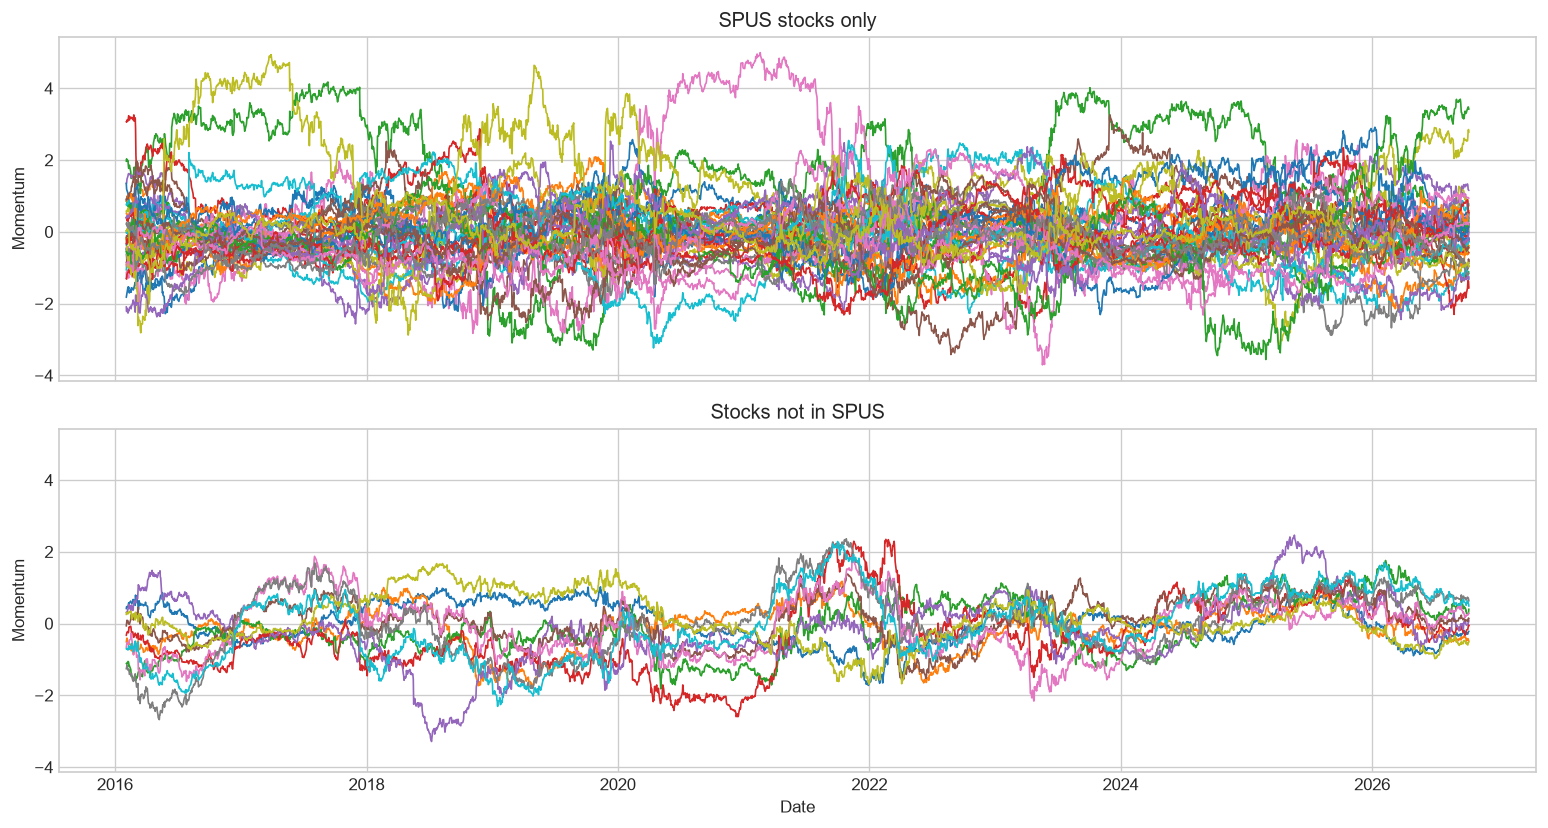

In [61]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True)
axes[0].plot(mom_spus, lw=1)
axes[0].set_ylabel('Momentum')
axes[0].set_title('SPUS stocks only')
axes[1].plot(mom_diff, lw=1)
axes[1].set_ylabel('Momentum')
axes[1].set_xlabel('Date')
axes[1].set_title('Stocks not in SPUS')
plt.tight_layout()

## Volatility signal

In [63]:
vol_sp500 = volatility_signal(returns_sp500)
vol_spus = volatility_signal(returns_spus)

In [64]:
vol_diff = pd.concat(
    [vol_sp500.reindex(columns=columns_not_in_both),
     vol_spus.reindex(columns=columns_not_in_both)],
    axis=0
)

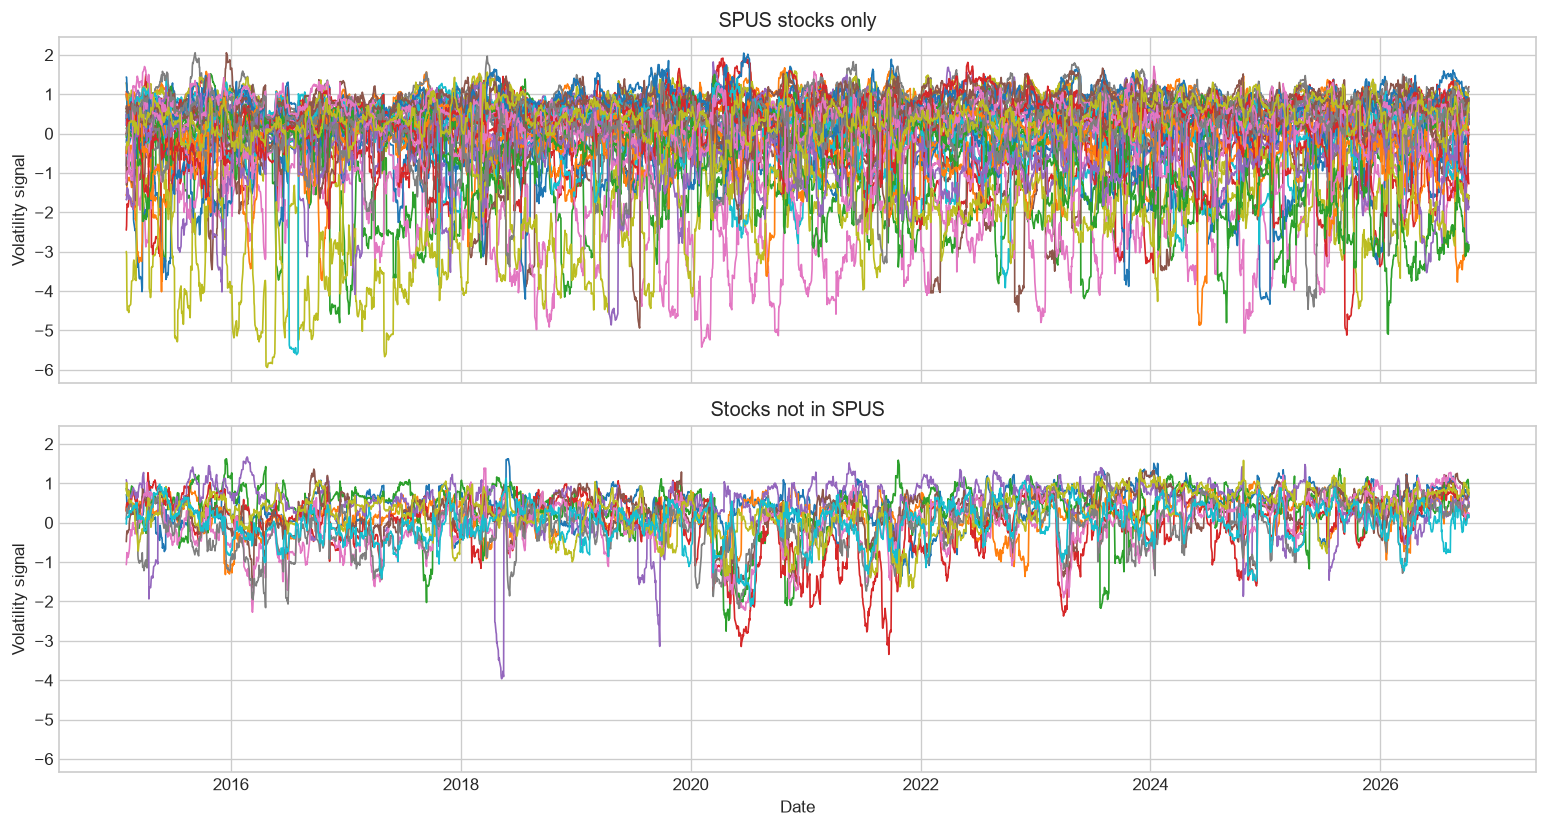

In [65]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True)
axes[0].plot(vol_spus, lw=1)
axes[0].set_ylabel('Volatility signal')
axes[0].set_title('SPUS stocks only')
axes[1].plot(vol_diff, lw=1)
axes[1].set_ylabel('Volatility signal')
axes[1].set_xlabel('Date')
axes[1].set_title('Stocks not in SPUS')
plt.tight_layout()

## Short term reversal

In [66]:
str_sp500 = short_term_reversal(returns_sp500)
str_spus = short_term_reversal(returns_spus)

In [67]:
str_diff = pd.concat(
    [str_sp500.reindex(columns=columns_not_in_both),
     str_spus.reindex(columns=columns_not_in_both)],
    axis=0
)

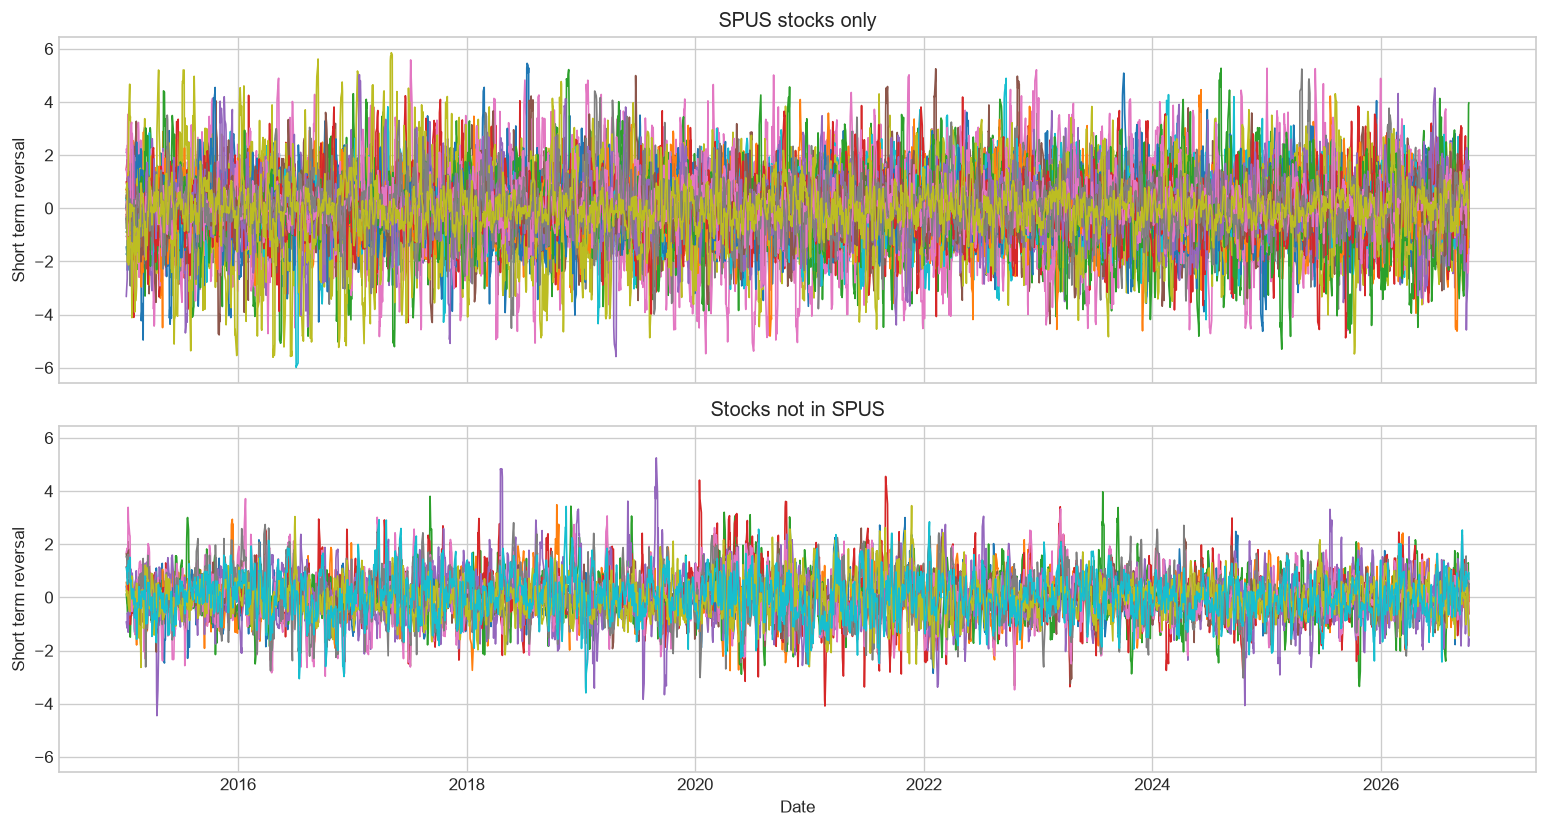

In [68]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True)
axes[0].plot(str_spus, lw=1)
axes[0].set_ylabel('Short term reversal')
axes[0].set_title('SPUS stocks only')
axes[1].plot(str_diff, lw=1)
axes[1].set_ylabel('Short term reversal')
axes[1].set_xlabel('Date')
axes[1].set_title('Stocks not in SPUS')
plt.tight_layout()

## Performance

In [73]:
# Transaction cost assumed to be 5 but not used here
# Pick 5 random stocks in SPUS and 5 random stocks not in SPUS

In [142]:
# Rerun this block for different stocks
summary_diff = np.random.choice(np.array(list(columns_not_in_both)), 10, replace=False)
summary_spus = np.random.choice(returns_spus.columns, 10, replace=False)

In [143]:
sharpe_spus = []
ann_return_spus = []
mdd_spus = []
for s in summary_spus:
    print(s)
    stats = summary(returns_sp500[s])
    sharpe_spus.append(float(stats['Sharpe (gross)']))
    ann_return_spus.append(float(stats['Annualised Return'][:-1]))
    mdd_spus.append(float(stats['Max Drawdown'][:-1]))

NVDA
  Annualised Return                            : 50.82%
  Sharpe (gross)                               : 1.10
  Max Drawdown                                 : -71.87%
MSFT
  Annualised Return                            : 20.18%
  Sharpe (gross)                               : 0.81
  Max Drawdown                                 : -40.61%
MRK
  Annualised Return                            : 9.18%
  Sharpe (gross)                               : 0.50
  Max Drawdown                                 : -45.61%
INTC
  Annualised Return                            : 1.79%
  Sharpe (gross)                               : 0.26
  Max Drawdown                                 : -82.94%
GOOGL
  Annualised Return                            : 19.61%
  Sharpe (gross)                               : 0.76
  Max Drawdown                                 : -47.95%
AVGO
  Annualised Return                            : 28.63%
  Sharpe (gross)                               : 0.84
  Max Drawdown             

In [144]:
sharpe_diff = []
ann_return_diff = []
mdd_diff = []
for s in summary_diff:
    print(s)
    stats = summary(returns_diff[s])
    sharpe_diff.append(float(stats['Sharpe (gross)']))
    ann_return_diff.append(float(stats['Annualised Return'][:-1]))
    mdd_diff.append(float(stats['Max Drawdown'][:-1]))

MA
  Annualised Return                            : 7.05%
  Sharpe (gross)                               : 0.65
  Max Drawdown                                 : -43.51%
V
  Annualised Return                            : 6.60%
  Sharpe (gross)                               : 0.65
  Max Drawdown                                 : -38.87%
JPM
  Annualised Return                            : 6.87%
  Sharpe (gross)                               : 0.63
  Max Drawdown                                 : -47.30%
BLK
  Annualised Return                            : 4.18%
  Sharpe (gross)                               : 0.44
  Max Drawdown                                 : -47.52%
RTX
  Annualised Return                            : 3.42%
  Sharpe (gross)                               : 0.39
  Max Drawdown                                 : -54.54%
WFC
  Annualised Return                            : 0.78%
  Sharpe (gross)                               : 0.21
  Max Drawdown                          

In [145]:
print('SPUS mean +/- std')
print(f'Sharpe : {np.mean(sharpe_spus):.2f} +/- {np.std(sharpe_spus):.2f}')
print(f'Annualised Return : {np.mean(ann_return_spus):.2f}% +/- {np.std(ann_return_spus):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_spus):.2f}% +/- {np.std(mdd_spus):.2f}%')
print('Diff mean +/- std')
print(f'Sharpe : {np.mean(sharpe_diff):.2f} +/- {np.std(sharpe_diff):.2f}')
print(f'Annualised Return : {np.mean(ann_return_diff):.2f}% +/- {np.std(ann_return_diff):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_diff):.2f}% +/- {np.std(mdd_diff):.2f}%')


SPUS mean +/- std
Sharpe : 0.63 +/- 0.24
Annualised Return : 17.05% +/- 13.49%
Max Drawdown : -50.40% +/- 15.30%
Diff mean +/- std
Sharpe : 0.49 +/- 0.13
Annualised Return : 4.88% +/- 1.85%
Max Drawdown : -51.64% +/- 8.41%
